# PB-12: Exploring the LendingClub training dataset

This notebook explores the dataset the risk model (PB-21) will be trained on and ends with
the recommended feature list. It answers five questions:

1. **What is in the data?** Size, period, and the loan outcomes it records.
2. **Which loans can the model learn from, and what counts as a default?**
3. **How balanced are the classes, and how much is missing?**
4. **Which columns may be used?** Every one of the 151 columns gets a role, and every
   exclusion has a reason (leakage, protected attribute, LendingClub's own pricing, ...).
5. **How does each candidate feature relate to default, and could a Maldivian borrower
   provide it on our form?** This sets PB-14's form fields.

The rules (label, population, features, column roles) live in `ml/dataset.py`, which the
training pipeline also imports, so the notebook and the model cannot disagree.
The charts are saved to `docs/report-notes/PB-12-*.png` for the report.

**To run:** download the data and build the Parquet file (see `risk-service/DATA.md`), then
`jupyter lab notebooks/PB-12-eda.ipynb` from `risk-service/`. Running it from top to bottom
takes about a minute. Only totals and rates are shown, never individual loans.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent  # this notebook lives in risk-service/notebooks/
sys.path.insert(0, str(ROOT))

from ml import dataset as d  # noqa: E402
import plot_style as style  # noqa: E402

style.apply()
pd.set_option("display.max_rows", 200, "display.max_colwidth", 140, "display.width", 200)

RAW = ROOT / "data" / "raw"
PARQUET = RAW / "accepted_2007_to_2018Q4.parquet"
CSV_GZ = RAW / "accepted_2007_to_2018Q4.csv.gz"
assert PARQUET.exists(), "Run `python -m ml.prepare` first (see risk-service/DATA.md)."

## 1. What is in the data

LendingClub was a US peer-to-peer lending platform: people asked for unsecured personal
loans of $500–$40,000 over 36 or 60 months, and investors funded them. The file holds every
loan it issued from 2007 to the end of 2018, with the borrower's application details,
credit-bureau data, and what happened to the loan.

In [2]:
schema = pq.read_schema(PARQUET)
assert set(schema.names) == set(d.COLUMN_ROLES), "every column must have a role in ml/dataset.py"

base = pd.read_parquet(PARQUET, columns=["loan_status", "issue_d", "term", "application_type", "last_pymnt_d"])
issue = d.parse_month(base["issue_d"].to_numpy())
snapshot = d.data_snapshot(base["last_pymnt_d"].to_numpy())
base["label"] = d.default_label(base["loan_status"].to_numpy()).to_numpy()

pd.Series(
    {
        "Loans (rows)": f"{len(base):,}",
        "Columns": len(schema.names),
        "Download (CSV, gzip)": f"{CSV_GZ.stat().st_size / 1e6:,.0f} MB" if CSV_GZ.exists() else "not present",
        "Parquet cache": f"{PARQUET.stat().st_size / 1e6:,.0f} MB",
        "Loans issued": f"{issue.min():%b %Y} to {issue.max():%b %Y}",
        "Data snapshot (latest payment in the file)": f"{snapshot:%b %Y}",
    },
    name="value",
).to_frame()

,value
Loans (rows),"2,260,668"
Columns,151
"Download (CSV, gzip)",393 MB
Parquet cache,302 MB
Loans issued,Jun 2007 to Dec 2018
Data snapshot (latest payment in the file),Mar 2019


In [3]:
status = base["loan_status"].value_counts().rename("loans").to_frame()
status["share"] = (status["loans"] / len(base)).map("{:.1%}".format)
status["label"] = status.index.map(lambda s: {0: "0 (paid)", 1: "1 (default)"}.get(d.OUTCOME_LABELS.get(s), "none (unfinished)"))
resolved = base["label"].notna()
print(f"Loans with a final outcome: {resolved.sum():,}; default rate among them: {base.loc[resolved, 'label'].mean():.2%}")
status

Loans with a final outcome: 1,348,099; default rate among them: 19.98%


,loans,share,label
loan_status,,,
Fully Paid,1076751,47.6%,0 (paid)
Current,878317,38.9%,none (unfinished)
Charged Off,268559,11.9%,1 (default)
Late (31-120 days),21467,0.9%,none (unfinished)
In Grace Period,8436,0.4%,none (unfinished)
Late (16-30 days),4349,0.2%,none (unfinished)
Does not meet the credit policy. Status:Fully Paid,1988,0.1%,0 (paid)
Does not meet the credit policy. Status:Charged Off,761,0.0%,1 (default)
Default,40,0.0%,1 (default)


## 2. The label and the modelling population

**Label.** A loan is a default (1) if it was charged off or reached LendingClub's
"Default" status (121+ days late); it is good (0) if it was fully paid. Loans that are
still running (Current, In Grace Period, Late) have no final outcome, so they get no label.

**Why not use every finished loan?** Because recent finished loans are a biased sample.
The chart below shows it: for loans issued from 2015 onwards, many have not finished yet.
The ones that *have* finished are mostly early defaults and early payoffs, so the default
rate for those years is distorted. The fix is to keep only **matured cohorts**: loans whose
full term had ended by the snapshot, so every one of them had the chance to finish.

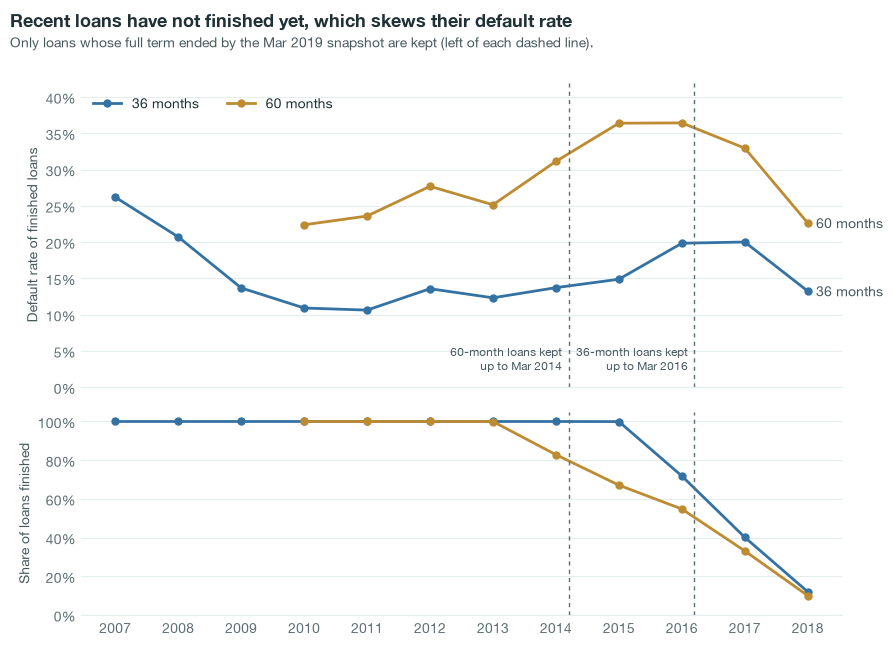

Saved docs/report-notes/PB-12-vintage-bias.png


In [4]:
base["year"] = issue.dt.year
base["matured"] = d.has_matured(base["issue_d"].to_numpy(), base["term"].to_numpy(), snapshot).to_numpy()
base["term_label"] = base["term"].str.strip()

vintage = (
    base.groupby(["term_label", "year"])
    .agg(loans=("label", "size"), finished=("label", lambda s: s.notna().mean()), default_rate=("label", "mean"))
    .reset_index()
)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True, height_ratios=[3, 2])
for term, colour in [("36 months", style.PAID), ("60 months", style.TERM_60)]:
    v = vintage[vintage["term_label"] == term]
    top.plot(v["year"], v["default_rate"], color=colour, marker="o", markersize=5, label=term)
    bottom.plot(v["year"], v["finished"], color=colour, marker="o", markersize=5)
    top.annotate(term, (v["year"].iloc[-1], v["default_rate"].iloc[-1]), xytext=(6, 0),
                 textcoords="offset points", va="center", color=style.INK_SECONDARY)
for cut, text in [(2014.2, "60-month loans kept\nup to Mar 2014"), (2016.2, "36-month loans kept\nup to Mar 2016")]:
    for ax in (top, bottom):
        ax.axvline(cut, color=style.AXIS, linewidth=1, linestyle=(0, (3, 3)))
    top.text(cut - 0.1, 0.02, text, ha="right", va="bottom", fontsize=8.5, color=style.INK_SECONDARY)
top.set_ylim(0, 0.42)
style.percent_axis(top.yaxis)
top.set_ylabel("Default rate of finished loans")
top.legend(loc="upper left", ncols=2)
bottom.set_ylim(0, 1.05)
style.percent_axis(bottom.yaxis)
bottom.set_ylabel("Share of loans finished")
bottom.set_xticks(range(2007, 2019))
style.frame(fig, "Recent loans have not finished yet, which skews their default rate",
            "Only loans whose full term ended by the Mar 2019 snapshot are kept (left of each dashed line).")
fig.tight_layout()
style.show(fig, "vintage-bias")

In [5]:
individual = base["application_type"].eq("Individual")
steps = [
    ("All loans in the file", pd.Series(True, index=base.index)),
    ("Individual applications (our platform has one borrower per request)", individual),
    ("... whose full term had ended by the snapshot", individual & base["matured"]),
    ("... with a final outcome: the modelling population", individual & base["matured"] & resolved),
]
funnel = pd.DataFrame(
    [
        {"step": name, "loans": int(mask.sum()), "share of file": f"{mask.mean():.1%}",
         "default rate (finished loans)": f"{base.loc[mask & resolved, 'label'].mean():.2%}"}
        for name, mask in steps
    ]
)
funnel

,step,loans,share of file,default rate (finished loans)
0,All loans in the file,2260668,100.0%,19.98%
1,Individual applications (our platform has one borrower per request),2139958,94.7%,19.89%
2,... whose full term had ended by the snapshot,784148,34.7%,15.19%
3,... with a final outcome: the modelling population,777399,34.4%,15.19%


In [6]:
# Load only the columns the features and the comparisons need.
needed = sorted({s for f in d.FEATURES for s in f.sources}
                | {"loan_status", "issue_d", "application_type", "verification_status", "int_rate", "grade"})
raw = pd.read_parquet(PARQUET, columns=needed)
pop = d.modelling_population(raw, snapshot)
del raw
X = d.build_features(pop)
y = pop["default"]
pop_issue = d.parse_month(pop["issue_d"].to_numpy())
print(f"Modelling population: {len(pop):,} loans issued {pop_issue.min():%b %Y} to {pop_issue.max():%b %Y}; "
      f"default rate {y.mean():.2%}")

Modelling population: 777,399 loans issued Jun 2007 to Mar 2016; default rate 15.19%


## 3. Class balance

Defaults are the minority class. A model that always answered "will repay" would be right
about 85% of the time and useless, so PB-21 must judge models on AUC and F1 rather than
accuracy, and handle the imbalance (class weights or SMOTE, inside the training folds only).

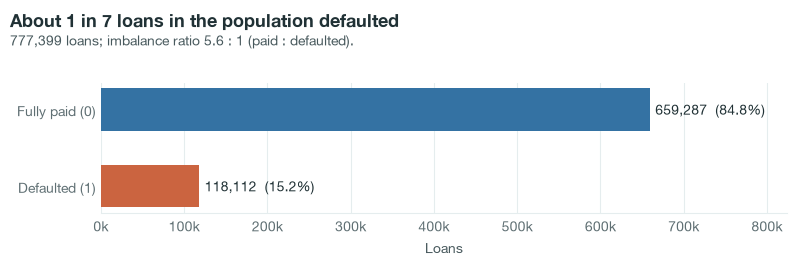

Saved docs/report-notes/PB-12-class-balance.png


In [7]:
counts = y.value_counts().sort_index()
labels = ["Fully paid (0)", "Defaulted (1)"]
fig, ax = plt.subplots(figsize=(8, 2.4))
ax.barh(labels, counts.values, color=[style.PAID, style.DEFAULTED], height=0.55)
for i, n in enumerate(counts.values):
    ax.text(n + counts.max() * 0.01, i, f"{n:,}  ({n / counts.sum():.1%})", va="center", color=style.INK)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlim(0, counts.max() * 1.25)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k"))
ax.set_xlabel("Loans")
style.frame(fig, f"About 1 in {round(1 / y.mean())} loans in the population defaulted",
            f"{len(y):,} loans; imbalance ratio {counts[0] / counts[1]:.1f} : 1 (paid : defaulted).")
fig.tight_layout()
style.show(fig, "class-balance")

## 4. Every column, and whether it may be used

Each of the 151 columns has exactly one role in `ml/dataset.py` (`COLUMN_ROLES`), and a test
checks that none is missed. The main reasons for leaving a column out:

- **after_scoring (leakage).** Our platform scores a request *before* it is listed and
  funded. Anything recorded later (the amount funded, payments received, recoveries,
  hardship plans, settlements, a FICO score pulled during repayment) would not exist at
  that moment. Many of these effectively contain the answer (a loan with recoveries has
  defaulted), so a model trained on them would look excellent and fail in real use.
- **lender_risk_output.** `grade`, `sub_grade`, `int_rate` and `installment` are
  LendingClub's own model output. Learning from them would copy their model instead of
  building ours, and an interest rate cannot exist in Shariah mode.
- **protected_or_proxy.** The data has no age, sex, race, religion or marital status
  (LendingClub did not publish them). It does have location (`zip_code`, `addr_state`) and
  free text (`emp_title`, `desc`, `title`), which can stand in for ethnicity, religion,
  health or identity, so these are left out. On our platform the equivalent, atoll or
  island, is left out of the model too.
- **selection_effect.** See section 7: verified incomes look *riskier* in this data.

In [8]:
catalogue = d.column_catalogue()
role_order = list(d.ROLE_REASONS)
by_role = (
    catalogue.groupby("role")
    .agg(columns=("column", "size"), examples=("column", lambda c: ", ".join(list(c)[:6]) + (" ..." if len(c) > 6 else "")))
    .reindex(role_order)
    .assign(reason=lambda t: t.index.map(d.ROLE_REASONS))
)
by_role

,columns,examples,reason
role,,,
feature,16,"loan_amnt, term, purpose, annual_inc, dti, emp_length ...",Used to build a feature (see FEATURES).
target,1,loan_status,The loan outcome; becomes the label.
population_filter,2,"issue_d, application_type",Only used to choose the modelling population or to work out a feature date.
identifier,3,"id, member_id, url",Identifies the loan or borrower; no meaning for risk.
after_scoring,40,"funded_amnt, funded_amnt_inv, pymnt_plan, out_prncp, out_prncp_inv, total_pymnt ...","Only known after our platform would score the request: funding, repayments, collections, hardship plans or settlements. Using it would l..."
lender_risk_output,4,"grade, sub_grade, int_rate, installment","LendingClub's own grade or price, produced by its model from the same inputs. Learning from it would copy their model, and an interest r..."
lender_operational,3,"initial_list_status, policy_code, disbursement_method","A LendingClub process setting, not something about the borrower."
protected_or_proxy,5,"zip_code, addr_state, emp_title, desc, title","Location or free text that can stand in for ethnicity, religion, health or identity. Left out for fairness."
selection_effect,1,verification_status,"LendingClub chose whom to verify (riskier-looking applicants), so verified loans default more. On our platform every borrower is verifie..."


In [9]:
# Columns with a specific note (the rest are explained by their role's reason above).
catalogue.loc[catalogue["note"] != "", ["column", "role", "note"]].reset_index(drop=True)

,column,role,note
0,loan_amnt,feature,Not used on its own: absolute US dollars do not transfer to MVR. Used in loan_to_income and repayment_burden.
1,annual_inc,feature,"Not used on its own, for the same reason. Used in the ratio features."
2,fico_range_high,feature,Always fico_range_low + 4; both feed fico_score.
3,funded_amnt,after_scoring,"Set when investors fund the loan, after our scoring step."
4,funded_amnt_inv,after_scoring,"Set when investors fund the loan, after our scoring step."
5,last_fico_range_high,after_scoring,"FICO pulled during repayment, so it already reflects missed payments."
6,last_fico_range_low,after_scoring,"FICO pulled during repayment, so it already reflects missed payments."
7,installment,lender_risk_output,Worked out from int_rate; repayment_burden is the interest-free version.
8,zip_code,protected_or_proxy,First 3 digits of a US ZIP code: a known proxy for race and income area.
9,addr_state,protected_or_proxy,US state; on our platform the equivalent (atoll or island) is left out too.


## 5. Missing values

Missing values are measured inside the modelling population. Each dot is one column.
Almost all the heavy gaps are in columns that are excluded anyway; the candidate features
are nearly complete.

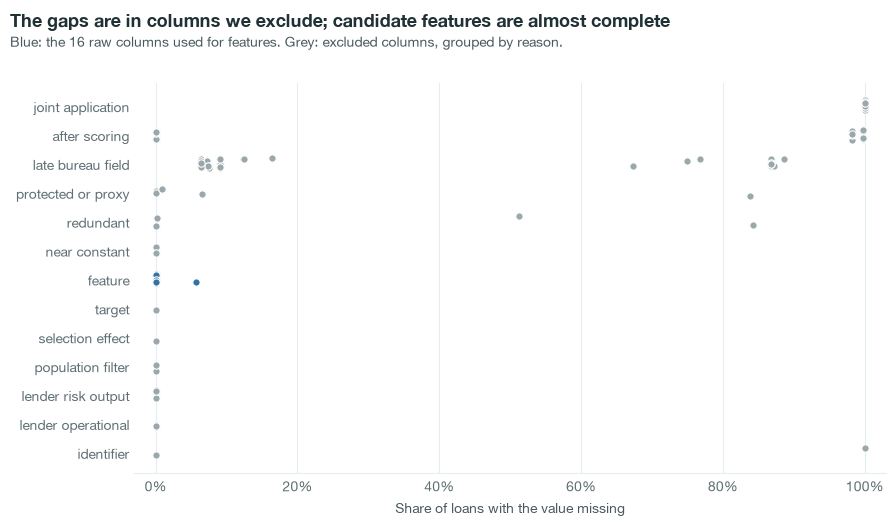

Saved docs/report-notes/PB-12-missing-values.png


,term_months,purpose_group,loan_to_income,repayment_burden,dti,emp_length_years,home_ownership,fico_score,credit_history_months,delinq_2yrs,inq_last_6mths,open_acc,total_acc,revol_util,pub_rec
missing,0.00%,0.00%,0.00%,0.00%,0.00%,5.73%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.06%,0.00%


In [10]:
rows = pop.index.to_numpy()
missing = {}
names = schema.names
for start in range(0, len(names), 20):
    chunk = pd.read_parquet(PARQUET, columns=names[start:start + 20])
    missing.update(chunk.iloc[rows].isna().mean().to_dict())
del chunk
catalogue["missing"] = catalogue["column"].map(missing)

order = catalogue.groupby("role")["missing"].median().sort_values().index.tolist()
rng = np.random.default_rng(12)  # fixed seed: same dot positions on every run
fig, ax = plt.subplots(figsize=(9, 5))
for i, role in enumerate(order):
    values = catalogue.loc[catalogue["role"] == role, "missing"].to_numpy()
    colour = style.PAID if role == "feature" else style.EXCLUDED
    ax.scatter(values, i + rng.uniform(-0.18, 0.18, len(values)), s=28, color=colour,
               edgecolor="white", linewidth=0.8, zorder=3)
ax.set_yticks(range(len(order)), [r.replace("_", " ") for r in order])
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
style.percent_axis(ax.xaxis)
ax.set_xlim(-0.03, 1.03)
ax.set_xlabel("Share of loans with the value missing")
style.frame(fig, "The gaps are in columns we exclude; candidate features are almost complete",
            "Blue: the 16 raw columns used for features. Grey: excluded columns, grouped by reason.")
fig.tight_layout()
style.show(fig, "missing-values")

feature_missing = X.isna().mean().rename("missing").to_frame()
feature_missing["missing"] = feature_missing["missing"].map("{:.2%}".format)
feature_missing.T

**What the gaps mean.** Only `emp_length_years` has a real gap (about 6%). It is kept as
missing, not filled in, because section 7 shows that borrowers who left it blank default
noticeably more often. XGBoost handles missing values natively; for logistic regression
PB-21 will fill them with the median plus a "was missing" indicator.

**What we leave out with the late bureau fields.** These columns started in 2012 or late
2015. The table below shows the strongest of them, measured only on the loans where they
are present (for the 87%-missing fields that is only loans from Dec 2015 to Mar 2016, so
those numbers are rough). Several carry real signal: `acc_open_past_24mths` comes close to
FICO and is missing for only 6.4% of loans. They are still left out because their gaps
track the issue date rather than the borrower and they have no Maldivian source. The
consequence is that the "full" benchmark set **understates** what bureau data could add,
so the accuracy gap PB-21 measures between "full" and "deployable" is a lower bound.

In [11]:
def single_auc(values, target):
    # Single-feature ROC AUC, folded so 0.5 = no signal and 1.0 = perfect ranking.
    # Categories are scored by their default rate (in-sample, which is fine for ranking).
    present = values.notna()
    values, target = values[present], target[present]
    if not pd.api.types.is_numeric_dtype(values):
        values = values.map(target.groupby(values).mean())
    auc = roc_auc_score(target, values)
    return max(auc, 1 - auc), ("higher = riskier" if auc >= 0.5 else "higher = safer")


late = [c for c, r in d.COLUMN_ROLES.items() if r == "late_bureau_field"]
late_values = pd.read_parquet(PARQUET, columns=late).iloc[rows].set_axis(pop.index)
late_table = pd.DataFrame(
    [{"column": c, "missing": missing[c], "AUC where present": single_auc(late_values[c], y)[0]} for c in late]
).sort_values("AUC where present", ascending=False)
del late_values
late_table.head(8).style.format({"missing": "{:.1%}", "AUC where present": "{:.3f}"}).hide(axis="index")

column,missing,AUC where present
open_rv_24m,86.7%,0.586
acc_open_past_24mths,6.4%,0.580
bc_open_to_buy,7.3%,0.573
num_tl_op_past_12m,9.0%,0.572
mths_since_rcnt_il,87.1%,0.570
inq_last_12m,86.7%,0.570
total_bc_limit,6.4%,0.568
open_rv_12m,86.7%,0.566


## 6. Distributions of the candidate features

Each panel compares the shape of a feature for loans that were repaid (blue) and loans that
defaulted (coral), drawn as densities so the two classes are comparable despite their
different sizes. Values are clipped at the 0.5th and 99.5th percentiles so a few extreme
incomes or balances do not squash the chart.

In [12]:
numeric = [f for f in d.FULL_FEATURES if f not in d.CATEGORICAL_FEATURES and f != "term_months"]
feature_set = {f.name: ("deployable" if f.feature_set == "deployable" else "bureau") for f in d.FEATURES}

X[numeric].describe(percentiles=[0.01, 0.5, 0.99]).T.round(2)

,count,mean,std,min,1%,50%,99%,max
loan_to_income,777395.0,0.20,0.11,0.0,0.03,0.19,0.46,1.34
repayment_burden,777395.0,0.06,0.03,0.0,0.01,0.06,0.15,0.45
dti,777398.0,17.70,8.28,0.0,1.83,17.18,37.38,49.95
emp_length_years,732818.0,5.91,3.67,0.0,0.00,6.00,10.00,10.00
fico_score,777399.0,697.47,31.21,612.0,662.00,692.00,797.10,847.50
credit_history_months,777370.0,194.13,90.85,6.0,46.00,176.00,477.00,852.00
delinq_2yrs,777370.0,0.31,0.86,0.0,0.00,0.00,4.00,30.00
inq_last_6mths,777370.0,0.70,1.01,0.0,0.00,0.00,4.00,33.00
open_acc,777370.0,11.33,5.25,0.0,3.00,10.00,28.00,84.00
total_acc,777370.0,24.68,11.76,1.0,5.00,23.00,60.00,176.00


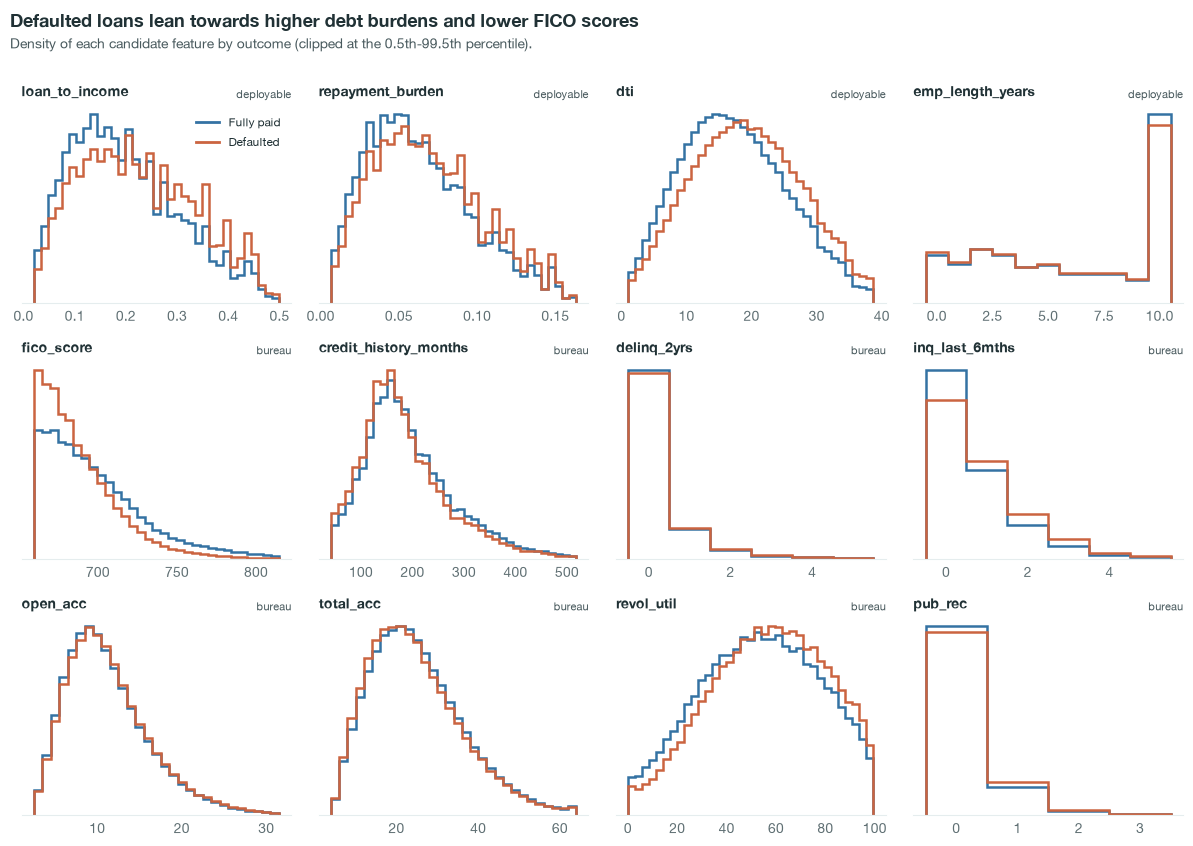

Saved docs/report-notes/PB-12-distributions.png


In [13]:
def is_whole(series):
    present = series.dropna()
    return bool((present == present.round()).all())


def histogram_bins(values, lo, hi):
    # Features with a limited set of common values (counts, years, FICO in steps of 5) get
    # one bin per value step, centred on the values; otherwise bins would cut between
    # values unevenly and draw a misleading comb.
    in_range = values[values.between(lo, hi)]
    counts = in_range.value_counts()
    common = np.sort(counts[counts >= 0.001 * len(in_range)].index.to_numpy())
    if 2 <= len(common) <= 100 and counts[common].sum() >= 0.95 * len(in_range):
        step = np.median(np.diff(common)) * max(1, int(np.ceil(len(common) / 40)))
        return np.arange(common[0] - step / 2, common[-1] + step, step)
    return np.linspace(lo, hi, 36)


fig, axes = plt.subplots(3, 4, figsize=(12, 8.2))
for ax, name in zip(axes.flat, numeric):
    values = X[name]
    lo, hi = values.quantile([0.005, 0.995])
    bins = histogram_bins(values, lo, hi)
    for label, colour in [(0, style.PAID), (1, style.DEFAULTED)]:
        ax.hist(values[(y == label) & values.between(lo, hi)], bins=bins, density=True,
                histtype="step", linewidth=1.8, color=colour)
    ax.set_title(name, fontsize=10)
    ax.text(1, 1.02, feature_set[name], transform=ax.transAxes, ha="right", va="bottom",
            fontsize=8, color=style.INK_SECONDARY)
    ax.set_yticks([])
    ax.grid(visible=False)
    ax.spines["bottom"].set_color(style.GRID)
axes.flat[0].legend(handles=[plt.Line2D([], [], color=style.PAID, label="Fully paid"),
                             plt.Line2D([], [], color=style.DEFAULTED, label="Defaulted")],
                    loc="upper right", fontsize=8.5)
style.frame(fig, "Defaulted loans lean towards higher debt burdens and lower FICO scores",
            "Density of each candidate feature by outcome (clipped at the 0.5th-99.5th percentile).")
fig.tight_layout()
style.show(fig, "distributions")

## 7. How each candidate feature relates to default

**Numeric features.** Loans are grouped into ten equal-sized bands (deciles) of each
feature, or by value for small counts. The line shows the default rate in each band; the
dashed line is the overall rate. A flat line means the feature carries little information
on its own.

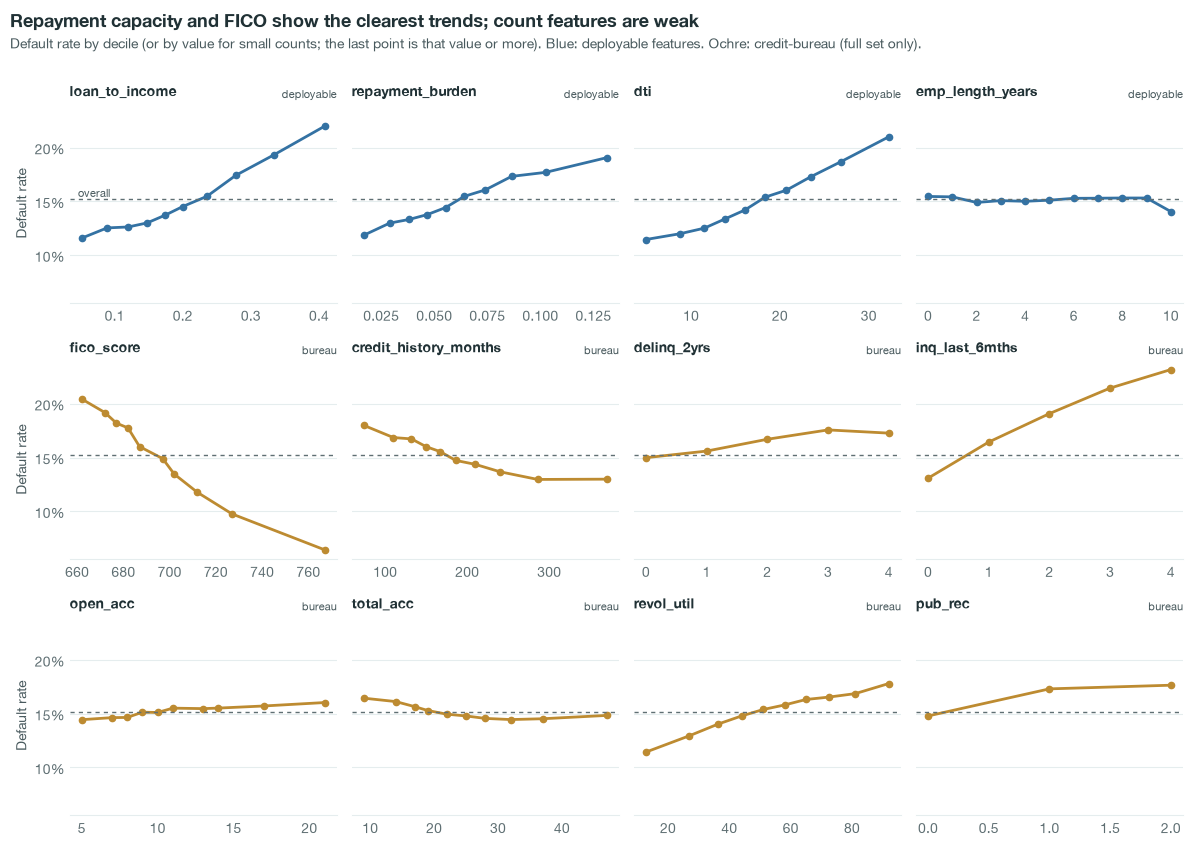

Saved docs/report-notes/PB-12-default-rate-by-feature.png


In [14]:
def default_rate_by_band(values, target):
    present = values.notna()
    values, target = values[present], target[present]
    top = values.quantile(0.99)
    if is_whole(values) and top <= 15:  # small counts: one band per value, last band = "top or more"
        centres = values.clip(upper=max(top, 1))
    else:
        bands = pd.qcut(values, 10, duplicates="drop")
        centres = values.groupby(bands, observed=True).transform("median")
    table = pd.DataFrame({"centre": centres, "default": target}).groupby("centre").agg(
        rate=("default", "mean"), loans=("default", "size"))
    return table[table["loans"] >= 200]  # hide bands too small to read


overall = y.mean()
fig, axes = plt.subplots(3, 4, figsize=(12, 8.2), sharey=True)
for ax, name in zip(axes.flat, numeric):
    table = default_rate_by_band(X[name], y)
    colour = style.PAID if feature_set[name] == "deployable" else style.TERM_60
    ax.plot(table.index, table["rate"], color=colour, marker="o", markersize=4.5)
    ax.axhline(overall, color=style.AXIS, linewidth=1, linestyle=(0, (3, 3)))
    ax.set_title(name, fontsize=10)
    ax.text(1, 1.02, feature_set[name], transform=ax.transAxes, ha="right", va="bottom",
            fontsize=8, color=style.INK_SECONDARY)
    style.percent_axis(ax.yaxis)
axes.flat[0].text(0.02, overall, " overall", transform=axes.flat[0].get_yaxis_transform(),
                  va="bottom", fontsize=8, color=style.INK_SECONDARY)
for ax in axes[:, 0]:
    ax.set_ylabel("Default rate")
style.frame(fig, "Repayment capacity and FICO show the clearest trends; count features are weak",
            "Default rate by decile (or by value for small counts; the last point is that value or more). Blue: deployable features. Ochre: credit-bureau (full set only).")
fig.tight_layout()
style.show(fig, "default-rate-by-feature")

**Categorical features**, plus `emp_length` with its blanks shown, and
`verification_status`, which is *excluded*. It is shown here because it behaves the wrong way
round: loans with a verified income default more often. LendingClub chose to verify the
applicants who looked riskier, so in this data "verified" partly means "looked risky".
On our platform every borrower is verified (PB-11), so the feature would be the same for
everyone and the model could not use it.

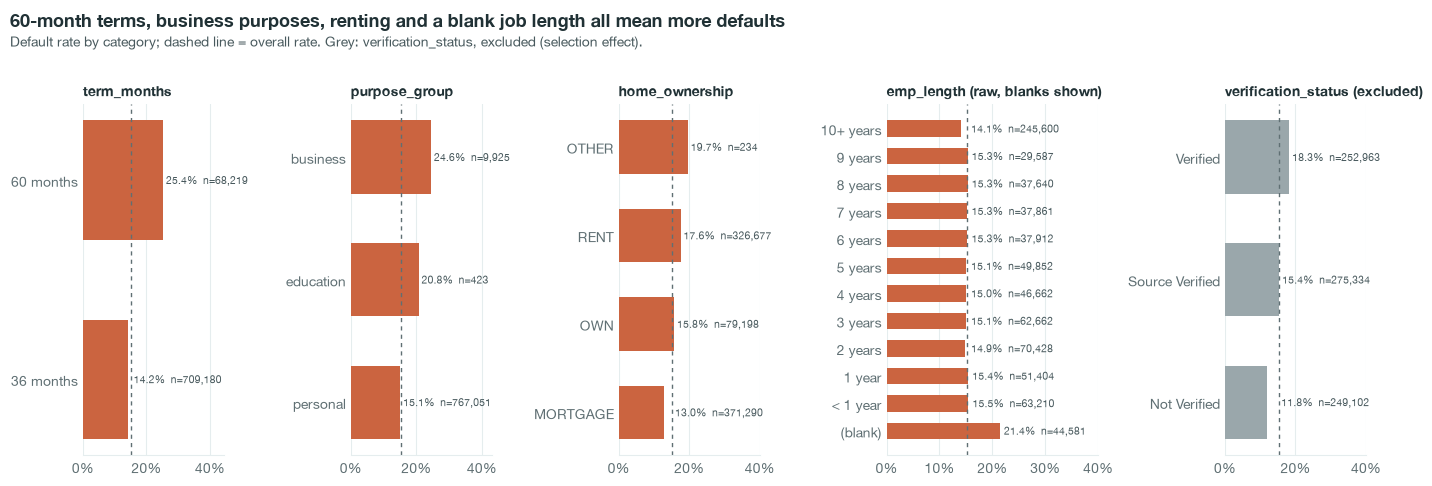

Saved docs/report-notes/PB-12-default-rate-by-category.png


In [15]:
panels = [
    ("term_months", X["term_months"].map(lambda m: f"{m:.0f} months"), False),
    ("purpose_group", X["purpose_group"], False),
    ("home_ownership", X["home_ownership"], False),
    ("emp_length (raw, blanks shown)", pop["emp_length"].fillna("(blank)"), False),
    ("verification_status (excluded)", pop["verification_status"], True),
]
emp_order = ["(blank)", "< 1 year", "1 year"] + [f"{n} years" for n in range(2, 10)] + ["10+ years"]

fig, axes = plt.subplots(1, 5, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1, 1, 1.5, 1]})
category_tables = {}
for ax, (title, values, excluded) in zip(axes, panels):
    table = pd.DataFrame({"v": values.to_numpy(), "y": y.to_numpy()}).groupby("v").agg(rate=("y", "mean"), loans=("y", "size"))
    table = table.reindex([c for c in emp_order if c in table.index]) if title.startswith("emp_length") else table.sort_values("rate")
    category_tables[title] = table
    ax.barh([str(i) for i in table.index], table["rate"], color=style.EXCLUDED if excluded else style.DEFAULTED, height=0.6)
    ax.axvline(overall, color=style.AXIS, linewidth=1, linestyle=(0, (3, 3)))
    for i, (rate, n) in enumerate(zip(table["rate"], table["loans"])):
        # Label to the right of both the bar and the dashed line, so the line never crosses the text.
        ax.text(max(rate, overall) + 0.008, i, f"{rate:.1%}  n={n:,}", va="center", fontsize=7.5, color=style.INK_SECONDARY)
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, max(0.4, table["rate"].max() * 1.75))
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    style.percent_axis(ax.xaxis)
style.frame(fig, "60-month terms, business purposes, renting and a blank job length all mean more defaults",
            "Default rate by category; dashed line = overall rate. Grey: verification_status, excluded (selection effect).")
fig.tight_layout()
style.show(fig, "default-rate-by-category")

**Single-feature strength.** The ROC AUC of each feature used on its own (0.5 = no better
than chance). Single features in credit scoring are usually weak (0.5–0.65); the model's
job is to combine them. LendingClub's own `int_rate` and `grade` are shown in grey for
reference: they are the strongest single columns *because* they are the output of
LendingClub's model, which is exactly why they are excluded.

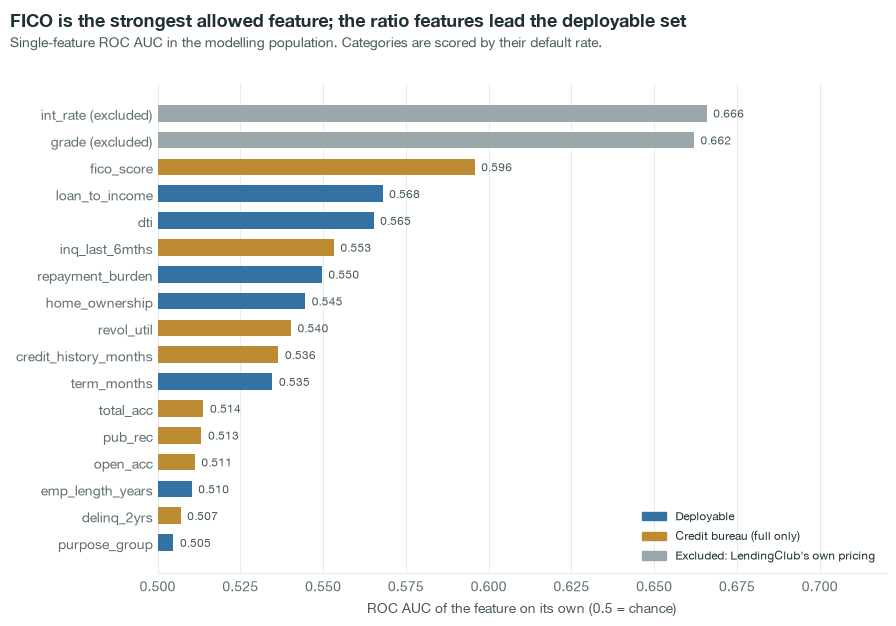

Saved docs/report-notes/PB-12-feature-strength.png


feature,set,AUC,direction
int_rate (excluded),excluded,0.666,higher = riskier
grade (excluded),excluded,0.662,higher = riskier
fico_score,bureau,0.596,higher = safer
loan_to_income,deployable,0.568,higher = riskier
dti,deployable,0.565,higher = riskier
inq_last_6mths,bureau,0.553,higher = riskier
repayment_burden,deployable,0.550,higher = riskier
home_ownership,deployable,0.545,higher = riskier
revol_util,bureau,0.540,higher = riskier
credit_history_months,bureau,0.536,higher = safer


In [16]:
strength = pd.DataFrame(
    [{"feature": name, "set": feature_set[name], **dict(zip(["AUC", "direction"], single_auc(X[name], y)))} for name in d.FULL_FEATURES]
    + [{"feature": f"{name} (excluded)", "set": "excluded", **dict(zip(["AUC", "direction"], single_auc(pop[name], y)))}
       for name in ["int_rate", "grade"]]
).sort_values("AUC")

colours = {"deployable": style.PAID, "bureau": style.TERM_60, "excluded": style.EXCLUDED}
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(strength["feature"], strength["AUC"] - 0.5, left=0.5, color=strength["set"].map(colours), height=0.62)
for i, auc in enumerate(strength["AUC"]):
    ax.text(auc + 0.002, i, f"{auc:.3f}", va="center", fontsize=8.5, color=style.INK_SECONDARY)
ax.set_xlim(0.5, 0.72)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("ROC AUC of the feature on its own (0.5 = chance)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=l) for l, c in
                   [("Deployable", style.PAID), ("Credit bureau (full only)", style.TERM_60),
                    ("Excluded: LendingClub's own pricing", style.EXCLUDED)]],
          loc="lower right", fontsize=8.5)
style.frame(fig, "FICO is the strongest allowed feature; the ratio features lead the deployable set",
            "Single-feature ROC AUC in the modelling population. Categories are scored by their default rate.")
fig.tight_layout()
style.show(fig, "feature-strength")

strength.sort_values("AUC", ascending=False).style.format({"AUC": "{:.3f}"}).hide(axis="index")

**Overlap between features.** Spearman rank correlation between the numeric candidates.
Strongly correlated pairs carry much of the same information; tree models cope with this,
but it matters when reading logistic-regression coefficients and SHAP values (PB-23).

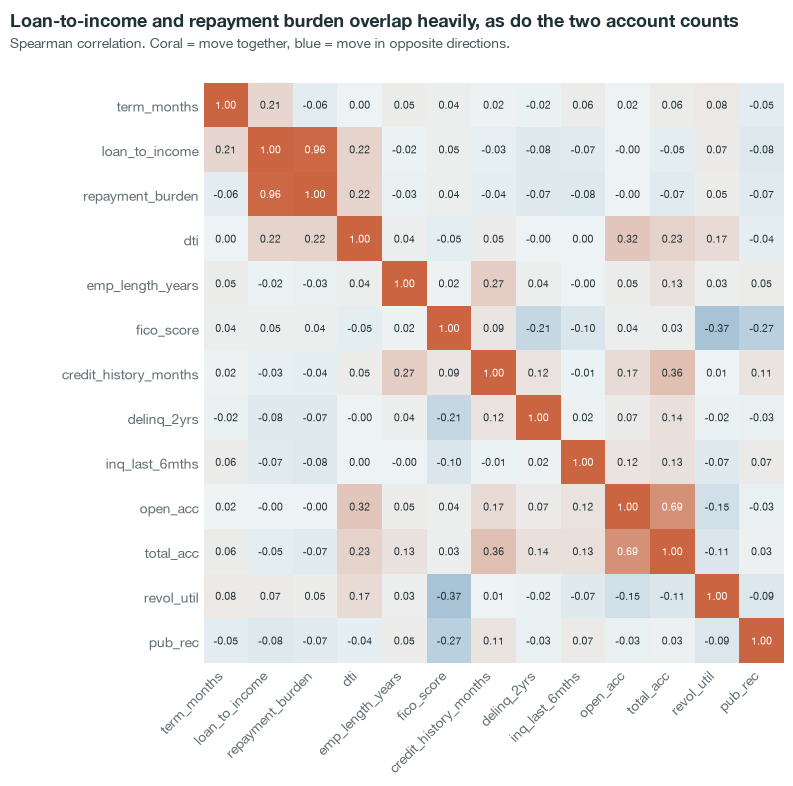

Saved docs/report-notes/PB-12-correlation.png


,,rho
loan_to_income,repayment_burden,0.96
open_acc,total_acc,0.69


In [17]:
from matplotlib.colors import LinearSegmentedColormap

corr_features = ["term_months"] + numeric
corr = X[corr_features].corr(method="spearman")
cmap = LinearSegmentedColormap.from_list("diverging", [style.PAID, style.MIDPOINT, style.DEFAULTED])

fig, ax = plt.subplots(figsize=(9, 7.6))
ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
for i in range(len(corr)):
    for j in range(len(corr)):
        value = corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(value) > 0.6 else style.INK)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(visible=False)
ax.spines["bottom"].set_visible(False)
style.frame(fig, "Loan-to-income and repayment burden overlap heavily, as do the two account counts",
            "Spearman correlation. Coral = move together, blue = move in opposite directions.")
fig.tight_layout()
style.show(fig, "correlation")

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("rho")
pairs[pairs.abs() >= 0.5].sort_values(key=abs, ascending=False).round(2).to_frame()

## 8. Recommended feature list

Two feature sets (recorded in `docs/decisions.md`):

- **Deployable** (7 features): only fields our PB-13 request and PB-14 financial-information
  form can collect. **The production model must use only this set.** It covers three of
  the four IR groups: application, repayment capacity and stability.
- **Full** (15 features): the deployable set plus 8 credit-bureau fields. PB-21 trains it
  as a **benchmark** to measure how much accuracy the deployable model gives up by not
  having bureau data. It is never served to users.

The credit-history group is empty in the deployable set: a Maldivian borrower has no FICO
score, and the MMA Credit Information System self-inquiry report gives partial history that
an admin would have to type in. That gap is the main limitation to state in the report, and
PB-49 plans how the platform's own repayment records can fill it over time.

Raw amounts (`loan_amnt`, `annual_inc`) are used only inside ratios. Absolute US-dollar
values do not carry over to MVR or to Maldivian income levels, but a loan-to-income ratio does.

In [18]:
features = d.feature_table()
features[["feature", "IR group", "set", "built from", "on our form?", "Maldives note"]]

,feature,IR group,set,built from,on our form?,Maldives note
0,term_months,application,deployable + full,term,yes,"Yes: tenure on the PB-13 request. LendingClub only has 36 and 60 months, so a shorter tenure is outside what the model has seen."
1,purpose_group,application,deployable + full,purpose,yes,"Yes: PB-13 purpose (start-up and growth map to business). Education has very few training loans, so the model can say little about it."
2,loan_to_income,repayment capacity,deployable + full,"loan_amnt, annual_inc",yes,"Yes: amount (PB-13) / declared annual income (PB-14). A ratio, so it carries over from US dollars to MVR, unlike the raw amounts."
3,repayment_burden,repayment capacity,deployable + full,"loan_amnt, term, annual_inc",yes,Yes: worked out from the PB-13 amount and tenure and the PB-14 income.
4,dti,repayment capacity,deployable + full,dti,yes,"Yes: PB-14 asks for monthly repayments on existing loans and cards, backed by a bank statement; the platform works out the percentage."
5,emp_length_years,stability,deployable + full,emp_length,yes,"Yes: years in current job or running the business (PB-14), backed by an employment letter or business registration."
6,home_ownership,stability,deployable + full,home_ownership,yes,"Yes, but living in a family-owned home is common in the Maldives and has no clear LendingClub match. PB-14 should offer it and map it to..."
7,fico_score,credit history,full only,"fico_range_low, fico_range_high",no,"No: there is no FICO-style score in the Maldives. The MMA Credit Information System self-inquiry report lists facilities and repayments,..."
8,credit_history_months,credit history,full only,"earliest_cr_line, issue_d",partial,"Partial: date of the first facility on a CIS self-inquiry report, typed in by an admin. Only covers banks and finance companies."
9,delinq_2yrs,credit history,full only,delinq_2yrs,partial,Partial: late repayments on a CIS self-inquiry report.


In [19]:
# What PB-14's form must collect so the platform can work out every deployable feature.
pd.DataFrame(
    [
        ("Amount requested", "PB-13", "loan_to_income, repayment_burden"),
        ("Tenure in months", "PB-13", "term_months, repayment_burden"),
        ("Purpose (start-up / growth / education / personal)", "PB-13", "purpose_group"),
        ("Annual income (MVR)", "PB-14", "loan_to_income, repayment_burden, dti"),
        ("Monthly repayments on existing loans and cards (MVR), excluding rent or housing", "PB-14", "dti"),
        ("Years in current job or running the business", "PB-14", "emp_length_years"),
        ("Housing: rent / own / own with a home loan / family home", "PB-14", "home_ownership"),
    ],
    columns=["form field", "story", "feeds"],
)

,form field,story,feeds
0,Amount requested,PB-13,"loan_to_income, repayment_burden"
1,Tenure in months,PB-13,"term_months, repayment_burden"
2,Purpose (start-up / growth / education / personal),PB-13,purpose_group
3,Annual income (MVR),PB-14,"loan_to_income, repayment_burden, dti"
4,"Monthly repayments on existing loans and cards (MVR), excluding rent or housing",PB-14,dti
5,Years in current job or running the business,PB-14,emp_length_years
6,Housing: rent / own / own with a home loan / family home,PB-14,home_ownership


## 9. Findings

**Data.** 2,260,668 loans and 151 columns, issued Jun 2007 to Dec 2018 (snapshot Mar 2019).
1,348,099 have a final outcome, with a 19.98% default rate. Licence CC0 (public domain).

**Population and label.** 777,399 individual loans from matured cohorts (issued Jun 2007 to
Mar 2016), 118,112 of them defaulted: **15.19%**, an imbalance of 5.6 : 1. Without the
maturity filter, 2015-2016 60-month loans would show about 36% defaults instead of 25%, a
bias created by the snapshot date, not by the borrowers.

**Missing values** are not a problem for the candidate features: only `emp_length` has a
real gap (5.7%). The blank itself is informative (21.4% default vs 14-15.5% for any filled
value), but on our form the field will be required, so the model cannot rely on blanks.
The numeric years add little on their own (AUC 0.510).

**Strongest features.** FICO is the strongest allowed single feature (AUC 0.596). In the
deployable set, `loan_to_income` (0.568) and `dti` (0.565) lead, followed by
`repayment_burden`, `home_ownership` and `term_months`. LendingClub's own `int_rate` (0.666)
and `grade` (0.662) beat everything because they are its model's output; they are excluded.

**Weak or surprising.**
- `purpose_group` is weak overall (0.505) because 98.7% of loans are "personal", though the
  small business group defaults far more (24.6% vs 15.1%).
- `verification_status` runs backwards (verified 18.3% vs not verified 11.8%), a selection
  effect, so it is excluded.
- `loan_to_income` and `repayment_burden` are nearly the same signal (Spearman 0.96).
  Trees cope; for logistic regression PB-21 should keep one.

**The full set is a conservative benchmark.** Some excluded late bureau fields carry
signal: `acc_open_past_24mths` has AUC 0.580 with 6.4% missing. Leaving them out
understates what bureau data can add, so the gap PB-21 measures between "full" and
"deployable" is a lower bound.

**Recommended sets.**
- *Deployable* (production): `term_months`, `purpose_group`, `loan_to_income`,
  `repayment_burden`, `dti`, `emp_length_years`, `home_ownership`.
- *Full* (benchmark only): the above plus `fico_score`, `credit_history_months`,
  `delinq_2yrs`, `inq_last_6mths`, `open_acc`, `total_acc`, `revol_util`, `pub_rec`.

**Limitations to state in the report.** These are US consumer loans from 2007-2016 in US
dollars, not Maldivian SME or personal financing in MVR. The ratios travel better than
amounts, but the model's absolute probabilities will need recalibrating on local data
(PB-49). The deployable model has no credit-history features at all.